<a href="https://colab.research.google.com/github/helviuni9/Controle_Estoque/blob/main/Controle_Estoque.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sistema de Controle de Estoque
Projeto de Gestão de Projetos + simulação do sistema de estoque.
Código simples, feito para rodar célula por célula no Google Colab.

## Bibliotecas usadas
- **pandas**: trabalhar com tabelas (DataFrame)
- **numpy**: gerar números aleatórios para os dados fictícios
- **matplotlib.pyplot**: fazer gráficos

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1.1) TAP — dados do projeto
Aqui a gente só guarda as informações do projeto em variáveis e mostra na tela.

In [ ]:
nome_projeto = "Sistema de Controle de Estoque - Loja Vitoria Utilidades"
cliente = "Loja de varejo em Sao Jose do Rio Preto/SP, 2500 produtos, 12 funcionarios"
justificativa = "A loja nao tem controle de estoque inventario 1x por ano, reposicao no olho, 15% de divergencia e muita falta de produto."
objetivo = "Reduzir rupturas em 60% e o capital parado em 20%, em 6 semanas, gastando menos de R$ 12.000."

print("PROJETO:", nome_projeto)
print("CLIENTE:", cliente)
print("JUSTIFICATIVA:", justificativa)
print("OBJETIVO SMART:", objetivo)

PROJETO: Sistema de Controle de Estoque - Loja Vitoria Utilidades
CLIENTE: Loja de varejo em Sao Jose do Rio Preto/SP, 2500 produtos, 12 funcionarios
JUSTIFICATIVA: A loja nao tem controle de estoque inventario 1x por ano, reposicao no olho, 15% de divergencia e muita falta de produto.
OBJETIVO SMART: Reduzir rupturas em 60% e o capital parado em 20%, em 6 semanas, gastando menos de R$ 12.000.


## 1.2) EAP
É só uma lista de textos. O laço `for` imprime linha por linha.

In [ ]:
eap = [
    "1.0 Gerenciamento do Projeto",
    "    1.1 Documentacao (TAP e Atas)",
    "    1.2 Matriz de Riscos",
    "2.0 Engenharia de Dados (Python)",
    "    2.1 Coleta das planilhas de estoque e vendas",
    "    2.2 Script de limpeza dos dados (ETL)",
    "    2.3 Curva ABC e ponto de reposicao",
    "3.0 Visualizacao",
    "    3.1 Dashboard com semaforo de estoque",
    "    3.2 Relatorios em PDF/Excel",
    "4.0 Homologacao e Entrega",
    "    4.1 Testes com os usuarios (UAT)",
    "    4.2 Treinamento da equipe"
]

for linha in eap:
    print(linha)

1.0 Gerenciamento do Projeto
    1.1 Documentacao (TAP e Atas)
    1.2 Matriz de Riscos
2.0 Engenharia de Dados (Python)
    2.1 Coleta das planilhas de estoque e vendas
    2.2 Script de limpeza dos dados (ETL)
    2.3 Curva ABC e ponto de reposicao
3.0 Visualizacao
    3.1 Dashboard com semaforo de estoque
    3.2 Relatorios em PDF/Excel
4.0 Homologacao e Entrega
    4.1 Testes com os usuarios (UAT)
    4.2 Treinamento da equipe


## 1.3) Backlog — user stories em uma tabela
Cada user story tem: ID, o que o usuário quer, a sprint e a prioridade.

In [ ]:
backlog = pd.DataFrame([
    ["US-01", "Como gerente, quero ver um painel com semaforo dos produtos", "Sprint 1", "Alta"],
    ["US-02", "Como estoquista, quero alerta quando o produto chegar no minimo", "Sprint 2", "Alta"],
    ["US-03", "Como gerente, quero a curva ABC dos produtos", "Sprint 2", "Alta"],
    ["US-04", "Como estoquista, quero aviso se a planilha estiver com erro", "Sprint 1", "Alta"],
    ["US-05", "Como dono, quero lista de produtos parados ha mais de 6 meses", "Sprint 3", "Media"],
    ["US-06", "Como dono, quero exportar o relatorio em Excel", "Sprint 3", "Media"]
], columns=["ID", "User Story", "Sprint", "Prioridade"])

print(backlog)

      ID                                         User Story    Sprint  \
0  US-01  Como gerente, quero ver um painel com semaforo...  Sprint 1   
1  US-02  Como estoquista, quero alerta quando o produto...  Sprint 2   
2  US-03       Como gerente, quero a curva ABC dos produtos  Sprint 2   
3  US-04  Como estoquista, quero aviso se a planilha est...  Sprint 1   
4  US-05  Como dono, quero lista de produtos parados ha ...  Sprint 3   
5  US-06     Como dono, quero exportar o relatorio em Excel  Sprint 3   

  Prioridade  
0       Alta  
1       Alta  
2       Alta  
3       Alta  
4      Media  
5      Media  


## 1.4) Matriz RACI quem faz e quem aprova
A regra de ouro cada linha tem UM único 'A' (quem aprova).
O código conta quantos 'A' tem em cada linha e avisa se estiver errado.

In [ ]:
raci = pd.DataFrame([
    ["1.1 Documentacao",       "R/A", "C",   "C"],
    ["1.2 Matriz de Riscos",   "R/A", "C",   "C"],
    ["2.2 Script ETL",         "I",   "R/A", "I"],
    ["2.3 Curva ABC",          "I",   "R/A", "C"],
    ["3.1 Dashboard",          "C",   "C",   "R/A"],
    ["4.1 Testes (UAT)",       "R",   "C",   "A"]
], columns=["Entrega", "Ana (PM)", "Bruno (Dados)", "Carla (Front)"])

print(raci)
print()

# validacao: conta quantos 'A' existem em cada linha
for i in range(len(raci)):
    linha = raci.iloc[i]
    qtd_a = 0
    for valor in list(linha)[1:]:    # pula a coluna "Entrega"
        if "A" in valor:
            qtd_a = qtd_a + 1
    if qtd_a == 1:
        print(list(linha)[0], "-> OK, tem 1 'A'")
    else:
        print(list(linha)[0], "-> ERRO: tem", qtd_a, "'A'")

                Entrega Ana (PM) Bruno (Dados) Carla (Front)
0      1.1 Documentacao      R/A             C             C
1  1.2 Matriz de Riscos      R/A             C             C
2        2.2 Script ETL        I           R/A             I
3         2.3 Curva ABC        I           R/A             C
4         3.1 Dashboard        C             C           R/A
5      4.1 Testes (UAT)        R             C             A

1.1 Documentacao -> OK, tem 1 'A'
1.2 Matriz de Riscos -> OK, tem 1 'A'
2.2 Script ETL -> OK, tem 1 'A'
2.3 Curva ABC -> OK, tem 1 'A'
3.1 Dashboard -> OK, tem 1 'A'
4.1 Testes (UAT) -> OK, tem 1 'A'


## 1.5) Gantt cronograma em barras
Em vez de mexer com datas complicadas, cada atividade tem:
- `dias[0]`  em que dia começa (contando do dia 1 do projeto)
- `dias[1]` quantos dias dura

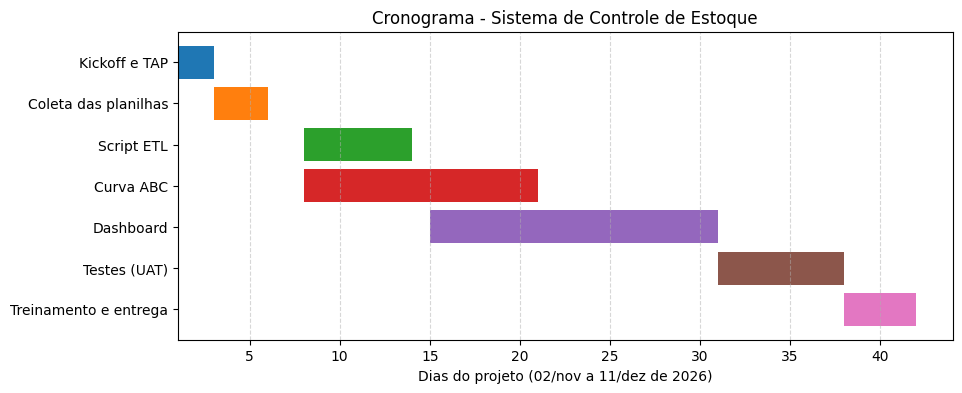

In [ ]:
atividades = ["Kickoff e TAP", "Coleta das planilhas", "Script ETL",
              "Curva ABC", "Dashboard", "Testes (UAT)", "Treinamento e entrega"]
comeca =   [1,  3,  8,  8, 15, 31, 38]   # dia de inicio
duracao =  [2,  3,  6, 13, 16,  7,  4]   # quantos dias cada uma dura

plt.figure(figsize=(10, 4))
for i in range(len(atividades)):
    plt.barh(i, duracao[i], left=comeca[i])
plt.yticks(range(len(atividades)), atividades)
plt.xlabel("Dias do projeto (02/nov a 11/dez de 2026)")
plt.title("Cronograma - Sistema de Controle de Estoque")
plt.gca().invert_yaxis()   # coloca a primeira atividade em cima
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.show()

## 1.6) Orçamento — soma simples com laço
`subtotal` começa em 0 e vai somando o valor de cada item.
Depois calcula 10% de contingência e o total.

In [ ]:
itens = ["Servidor AWS (6 meses)", "Dominio .com.br", "Power BI (3 meses)",
         "Horas Ana (PM)", "Horas Bruno (Dados)", "Horas Carla (Front)"]
valores = [900.00, 40.00, 165.00, 1600.00, 4000.00, 3600.00]

subtotal = 0
for v in valores:
    subtotal = subtotal + v

contingencia = subtotal * 0.10   # 10% sobre o subtotal
total = subtotal + contingencia

for i in range(len(itens)):
    print(itens[i], "-> R$", valores[i])
print("-------------------------")
print("Subtotal:      R$", subtotal)
print("Contingencia:  R$", contingencia)
print("TOTAL:         R$", total)

if total < 12000:
    print("OK! Dentro do teto de R$ 12.000 do objetivo SMART.")
else:
    print("ATENCAO! Estourou o teto de R$ 12.000.")

Servidor AWS (6 meses) -> R$ 900.0
Dominio .com.br -> R$ 40.0
Power BI (3 meses) -> R$ 165.0
Horas Ana (PM) -> R$ 1600.0
Horas Bruno (Dados) -> R$ 4000.0
Horas Carla (Front) -> R$ 3600.0
-------------------------
Subtotal:      R$ 10305.0
Contingencia:  R$ 1030.5
TOTAL:         R$ 11335.5
OK! Dentro do teto de R$ 12.000 do objetivo SMART.


## 1.7) Riscos - lista com plano B
Só imprimir os riscos e o que faremos se acontecerem.

In [ ]:
riscos = [
    ["Risco 1: cliente atrasar as planilhas", "Alta", "Usar um dataset ficticio (do Kaggle) ate a planilha real chegar"],
    ["Risco 2: planilha com datas quebradas e dados nulos", "Media", "Script de limpeza com try/except, que separa as linhas com erro"],
    ["Risco 3: membro da equipe ficar doente", "Baixa", "Codigo todo no GitHub com explicacoes, para outro assumir"]
]

for r in riscos:
    print("PROBLEMA:", r[0])
    print("CHANCE:  ", r[1])
    print("PLANO B: ", r[2])
    print()

PROBLEMA: Risco 1: cliente atrasar as planilhas
CHANCE:   Alta
PLANO B:  Usar um dataset ficticio (do Kaggle) ate a planilha real chegar

PROBLEMA: Risco 2: planilha com datas quebradas e dados nulos
CHANCE:   Media
PLANO B:  Script de limpeza com try/except, que separa as linhas com erro

PROBLEMA: Risco 3: membro da equipe ficar doente
CHANCE:   Baixa
PLANO B:  Codigo todo no GitHub com explicacoes, para outro assumir



---
# PARTE TÉCNICA simulação do sistema de estoque

## 2.1) Criar dados fictícios da loja
Criamos 50 produtos com números aleatórios, e deixamos a base "sujinha" de propósito
duplicados, valores vazios e datas erradas para o ETL ter o que limpar.

In [ ]:
# ==========================================
# ETAPA 2.1: GERAÇÃO DE DADOS SIMULADOS (SINTÉTICOS)
# ==========================================

# Definimos uma semente aleatória fixa para garantir que os números
# gerados sejam sempre os mesmos toda vez que rodarmos esta célula.
np.random.seed(42)

produtos = []

# Simulamos um catálogo de 50 produtos diferentes
for i in range(1, 51):
    produtos.append({
        "sku": f"LV-{1000 + i}",                                    # Código identificador único do produto
        "estoque_atual": int(np.random.randint(0, 300)),             # Saldo atual de itens no armazém
        "estoque_minimo": int(np.random.randint(10, 80)),            # Limite mínimo de segurança desejado
        "vendas_12m": int(np.random.exponential(300)),               # Volume histórico de vendas nos últimos 12 meses
        "dias_parado": int(np.random.randint(0, 400))                # Há quantos dias o produto não registra saída
    })

# Convertendo a lista de dicionários em um DataFrame do Pandas (Tabela)
df = pd.DataFrame(produtos)

# --- Inserção proposital de "ruídos" para testar nossa limpeza (ETL) ---

# 1. Duplicamos duas linhas de propósito (as linhas dos índices 0 e 5)
df = pd.concat([df, df.iloc[[0, 5]]], ignore_index=True)

# 2. Introduzimos valores nulos (vazios/NaN) em estoque_atual para simular falha de preenchimento
df.loc[[3, 10, 25], "estoque_atual"] = np.nan

# 3. Criamos uma coluna de data totalmente corrompida com textos inválidos
df["ultima_venda"] = "data invalida"

print(f"[OK] Base criada com sucesso! Total de registros: {len(df)} linhas.")
print("\n--- Prévia dos dados criados (com erros propositais) ---")
display(df.head())

[OK] Base criada com sucesso! Total de registros: 52 linhas.

--- Prévia dos dados criados (com erros propositais) ---


,sku,estoque_atual,estoque_minimo,vendas_12m,dias_parado,ultima_venda
0,LV-1001,102.0,61,903,106,data invalida
1,LV-1002,71.0,70,272,121,data invalida
2,LV-1003,214.0,33,315,308,data invalida
3,LV-1004,NaN,39,71,191,data invalida
4,LV-1005,276.0,42,108,21,data invalida


## 2.2) ETL — limpeza dos dados
Três limpezas básicas:
1. `drop_duplicates()` — tira linhas repetidas
2. `fillna(0)` — preenche valores vazios com zero
3. `pd.to_datetime(errors="coerce")` — tenta converter a data; se não conseguir, vira vazio (NaT) sem quebrar o código

In [ ]:
# ==========================================
# ETAPA 2.2: PIPELINE DE ETL (LIMPEZA E TRATAMENTO)
# ==========================================

print(f"Quantidade de registros ANTES da limpeza: {len(df)}")

# 1) Remoção de Registros Duplicados
# Elimina linhas que são cópias exatas de outras já existentes.
df = df.drop_duplicates()

# 2) Tratamento de Valores Nulos (Missing Values)
# Onde o estoque_atual estava nulo (NaN), preenchemos com 0 assumindo que não há unidades.
df["estoque_atual"] = df["estoque_atual"].fillna(0)

# 3) Padronização e Correção de Datas
# Tentamos converter as datas corrompidas. O parâmetro 'errors="coerce"' garante que
# valores impossíveis de converter virem 'NaT' (Not a Time/Vazio) sem travar a execução do script.
try:
    df["ultima_venda"] = pd.to_datetime(df["ultima_venda"], errors="coerce", format="mixed")
    linhas_com_data_ruim = df["ultima_venda"].isna().sum()
    print(f"Conversão de datas processada. Datas inválidas encontradas: {linhas_com_data_ruim}")
except Exception as e:
    print(f"Erro inesperado no tratamento de datas: {e}")

print(f"Quantidade de registros DEPOIS da limpeza: {len(df)}")
print("\n--- Prévia dos dados limpos e prontos para análise ---")
display(df.head())

Quantidade de registros ANTES da limpeza: 52
Conversão de datas processada. Datas inválidas encontradas: 50
Quantidade de registros DEPOIS da limpeza: 50

--- Prévia dos dados limpos e prontos para análise ---


,sku,estoque_atual,estoque_minimo,vendas_12m,dias_parado,ultima_venda
0,LV-1001,102.0,61,903,106,NaT
1,LV-1002,71.0,70,272,121,NaT
2,LV-1003,214.0,33,315,308,NaT
3,LV-1004,0.0,39,71,191,NaT
4,LV-1005,276.0,42,108,21,NaT


## 2.3) Curva ABC  separar os produtos por importância
- Ordena do que mais vende para o que menos vende
- Acumula o % das vendas
- Ate 80% = classe A (poucos produtos, quase tudo da receita)
- De 80% a 95% = classe B
- Resto = classe C

In [ ]:
# ==========================================
# ETAPA 2.3: CLASSIFICAÇÃO PELA CURVA ABC
# ==========================================
# A curva ABC identifica a relevância dos produtos com base no faturamento/vendas:
# - Classe A: Poucos produtos de alta relevância (até 80% do volume acumulado)
# - Classe B: Produtos de relevância intermediária (de 80% a 95% do volume acumulado)
# - Classe C: Grande quantidade de produtos de baixo giro (restante de 95% a 100%)

# 1. Ordenamos a tabela do produto mais vendido para o menos vendido
df = df.sort_values("vendas_12m", ascending=False).reset_index(drop=True)

# 2. Calculamos a representatividade percentual (%) de vendas de cada item individualmente
df["pct"] = 100 * df["vendas_12m"] / df["vendas_12m"].sum()

# 3. Calculamos a soma acumulada passo a passo (cumsum)
df["pct_acumulado"] = df["pct"].cumsum()

# 4. Criamos uma função de classificação baseada nas faixas de corte padrão
def classificar_faixa_abc(porcentagem_acumulada):
    if porcentagem_acumulada <= 80:
        return "A"
    elif porcentagem_acumulada <= 95:
        return "B"
    else:
        return "C"

# 5. Aplicamos a função linha por linha para rotular cada produto
df["curva_abc"] = df["pct_acumulado"].apply(classificar_faixa_abc)

# Mostramos a contagem geral de produtos em cada classe
print("--- Distribuição de Produtos por Classe ---")
print(df["curva_abc"].value_counts())

print("\n--- Top 5 Produtos da Classe A (Foco Estratégico de Reposição) ---")
display(df[df["curva_abc"] == "A"][["sku", "vendas_12m", "pct_acumulado"]].head())

--- Distribuição de Produtos por Classe ---
curva_abc
A    22
C    15
B    13
Name: count, dtype: int64

--- Top 5 Produtos da Classe A (Foco Estratégico de Reposição) ---


,sku,vendas_12m,pct_acumulado
0,LV-1008,1226,10.092196
1,LV-1001,903,17.525519
2,LV-1015,841,24.448469
3,LV-1032,796,31.000988
4,LV-1022,739,37.084294


## 2.4) Semáforo de reposição — alertas
Compara o estoque atual com o mínimo:
- atual <= mínimo → **VERMELHO** (repor agora!)
- atual <= mínimo x 1,2 → **AMARELO** (atenção)
- senão → **VERDE** (ok)

In [ ]:
# ==========================================
# ETAPA 2.4: REGRAS DO SEMÁFORO DE ALERTA
# ==========================================
# Analisamos a saúde do estoque comparando o saldo atual com o mínimo necessário:
# - Vermelho: Estoque crítico (estoque atual abaixo ou igual ao mínimo de segurança).
# - Amarelo: Atenção (estoque perto do limite, até 20% acima do mínimo).
# - Verde: Saudável (estoque seguro, acima de 20% do limite mínimo).

def calcular_status_semaforo(estoque_atual, estoque_minimo):
    limite_atencao = estoque_minimo * 1.20

    # Como tratamos valores nulos preenchendo com 0, garantimos a comparação correta convertendo para float
    atual = float(estoque_atual)
    minimo = float(estoque_minimo)

    if atual <= minimo:
        return "VERMELHO"
    elif atual <= limite_atencao:
        return "AMARELO"
    else:
        return "VERDE"

# Aplicamos a lógica em cada linha e gravamos no DataFrame
status_alertas = []
for i in range(len(df)):
    status_alertas.append(
        calcular_status_semaforo(df.iloc[i]["estoque_atual"], df.iloc[i]["estoque_minimo"])
    )
df["alerta"] = status_alertas

# Exibimos o resumo de alertas do sistema
print("--- Resumo de Status de Alerta do Estoque ---")
print(df["alerta"].value_counts())

# Detalhamento de produtos em situação grave (Vermelho)
produtos_vermelhos = df[df["alerta"] == "VERMELHO"]
print(f"\nProdutos Críticos (VERMELHO): {len(produtos_vermelhos)} itens precisando de compras urgentes.")

print("\n--- Amostra de Produtos com Estoque Crítico ---")
display(produtos_vermelhos[["sku", "estoque_atual", "estoque_minimo"]].head(8))

--- Resumo de Status de Alerta do Estoque ---
alerta
VERDE       39
VERMELHO    10
AMARELO      1
Name: count, dtype: int64

Produtos Críticos (VERMELHO): 10 itens precisando de compras urgentes.

--- Amostra de Produtos com Estoque Crítico ---


,sku,estoque_atual,estoque_minimo
0,LV-1008,50.0,64
8,LV-1026,0.0,10
10,LV-1011,0.0,11
25,LV-1044,52.0,53
26,LV-1034,27.0,53
27,LV-1042,1.0,11
37,LV-1004,0.0,39
38,LV-1020,8.0,10


## 2.5) Gráfico — estoque atual vs. mínimo
Barras azuis = estoque atual. Linha vermelha tracejada = estoque mínimo.
Quando a barra fica abaixo da linha, é produto em alerta.

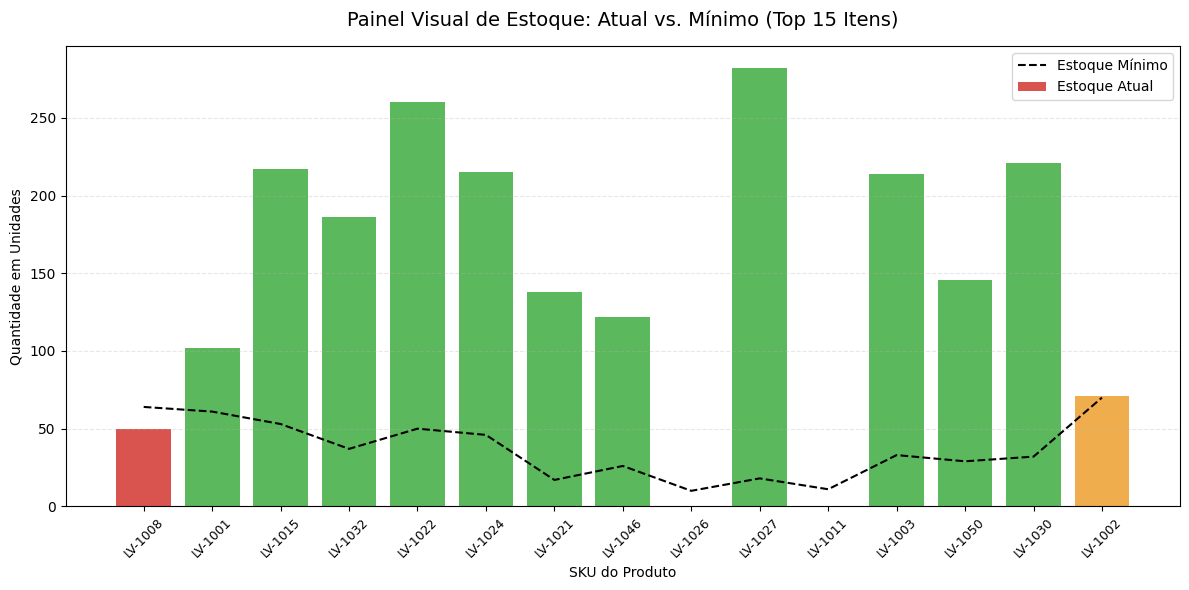

In [ ]:
# ==========================================
# ETAPA 2.5: VISUALIZAÇÃO GRÁFICA COMPARATIVA
# ==========================================

# Filtramos novamente os 15 produtos com maior volume de vendas para garantir que a coluna 'alerta' esteja atualizada
amostra = df.head(15).copy()

# Mapeamos dinamicamente as cores de cada barra de acordo com o alerta correspondente
mapa_cores = {
    "VERMELHO": "#d9534f",  # Vermelho agradável (Bootstrap style)
    "AMARELO": "#f0ad4e",   # Amarelo/Laranja
    "VERDE": "#5cb85c"     # Verde suave
}

cores_barras = [mapa_cores[alerta] for alerta in amostra["alerta"]]

# Configurações do layout do gráfico
plt.figure(figsize=(12, 6))

# 1. Plotagem das barras representando o estoque atual dos produtos
plt.bar(range(len(amostra)), amostra["estoque_atual"], color=cores_barras, label="Estoque Atual")

# 2. Plotagem da linha pontilhada preta indicando o limite de estoque mínimo individual
plt.plot(range(len(amostra)), amostra["estoque_minimo"], color="black", linestyle="--", linewidth=1.5, label="Estoque Mínimo")

# Detalhes e personalização do gráfico
plt.xticks(range(len(amostra)), amostra["sku"], rotation=45, fontsize=9)
plt.xlabel("SKU do Produto")
plt.ylabel("Quantidade em Unidades")
plt.title("Painel Visual de Estoque: Atual vs. Mínimo (Top 15 Itens)", fontsize=14, pad=15)
plt.legend(loc="upper right")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

## 2.6) Exportar relatório em Excel
Uma linha só salva a tabela final em um arquivo .xlsx.

In [ ]:
df.to_excel("relatorio_estoque.xlsx", index=False)
print("Relatorio salvo: relatorio_estoque.xlsx")
print("Colunas salvas:", list(df.columns))

Relatorio salvo: relatorio_estoque.xlsx
Colunas salvas: ['sku', 'estoque_atual', 'estoque_minimo', 'vendas_12m', 'dias_parado', 'ultima_venda', 'pct', 'pct_acumulado', 'curva_abc', 'alerta']
